# Step 3: our own radar flood map (Sentinel-1) vs the near-infrared maps

**Why radar:** it sends its own microwave pulse and listens for the echo, so clouds don't block it.
- Calm open water reflects the pulse away like a mirror, so it looks **dark**.
- Water under trees can bounce the pulse water → trunk → satellite, so it looks **brighter**.

**Pictures:** Sentinel-1A, orbit path 77: Sept 7 (before) and Sept 19 (after), 2018. NASA's free HyP3 service straightened them onto a 30 m map grid (`src/radar.py`).

**A mistake I caught:** my first radar pair (path 150, Sept 12 / Sept 18) only *touched* the box's corner: 6% and 0% coverage, so every pixel was blank. The archive search counts "touching" as a match. `radar.check_coverage()` now stops early unless a scene covers the whole box.

In [1]:
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import pandas as pd
from IPython.display import Image, display
step3 = importlib.import_module('03_radar_flood_map')
step3.main()

/Users/co2/Downloads/nc-hls-mapper/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


before: 20180907 covers 100% of the box
after: 20180919 covers 100% of the box
Both radar images already downloaded.


Radar open water: before 1.4 km2, after 2.2 km2
Radar new flood (whole box, clouds don't matter): 0.9 km2
  of which under optical clouds: 0.3 km2
Brightened by > 3.0 dB (hint of water under trees): 14.1 km2

Radar vs NIR (cloud-free pixels only):
   NIR rule  NIR flood km2  radar flood km2 (same area)  both km2  overlap (both / either)  share of NIR flood radar calls open water  share of NIR flood radar calls brightened
dark-in-NIR         11.278                        0.594     0.292                    0.025                                      0.028                                      0.090
   NIR-drop         16.478                        0.594     0.307                    0.018                                      0.020                                      0.085

Median radar brightness by optical category:
       optical category  VV before dB  VV after dB
               dry land          -8.9         -8.0
           water before         -15.3        -16.6
NIR flood (dark-in-NIR


Saved figures/03_*.png, results/03_*.csv, data/03_radar_vs_nir.tif


## Radar pictures (dark = calm open water)

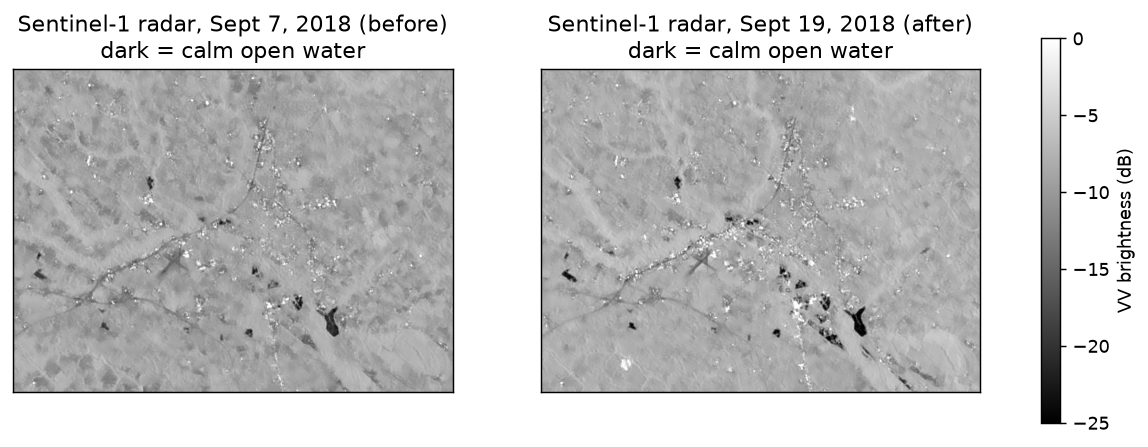

In [2]:
display(Image(filename='../figures/03_radar_before_after.png'))

## Radar vs near-infrared

In [3]:
display(pd.read_csv('../results/03_radar_vs_nir.csv'))
display(pd.read_csv('../results/03_radar_by_category.csv'))

,NIR rule,NIR flood km2,radar flood km2 (same area),both km2,overlap (both / either),share of NIR flood radar calls open water,share of NIR flood radar calls brightened
0,dark-in-NIR,11.278,0.594,0.292,0.025,0.028,0.090
1,NIR-drop,16.478,0.594,0.307,0.018,0.020,0.085


,optical category,VV before dB,VV after dB
0,dry land,-8.9,-8.0
1,water before,-15.3,-16.6
2,NIR flood (dark-in-NIR),-9.7,-9.5


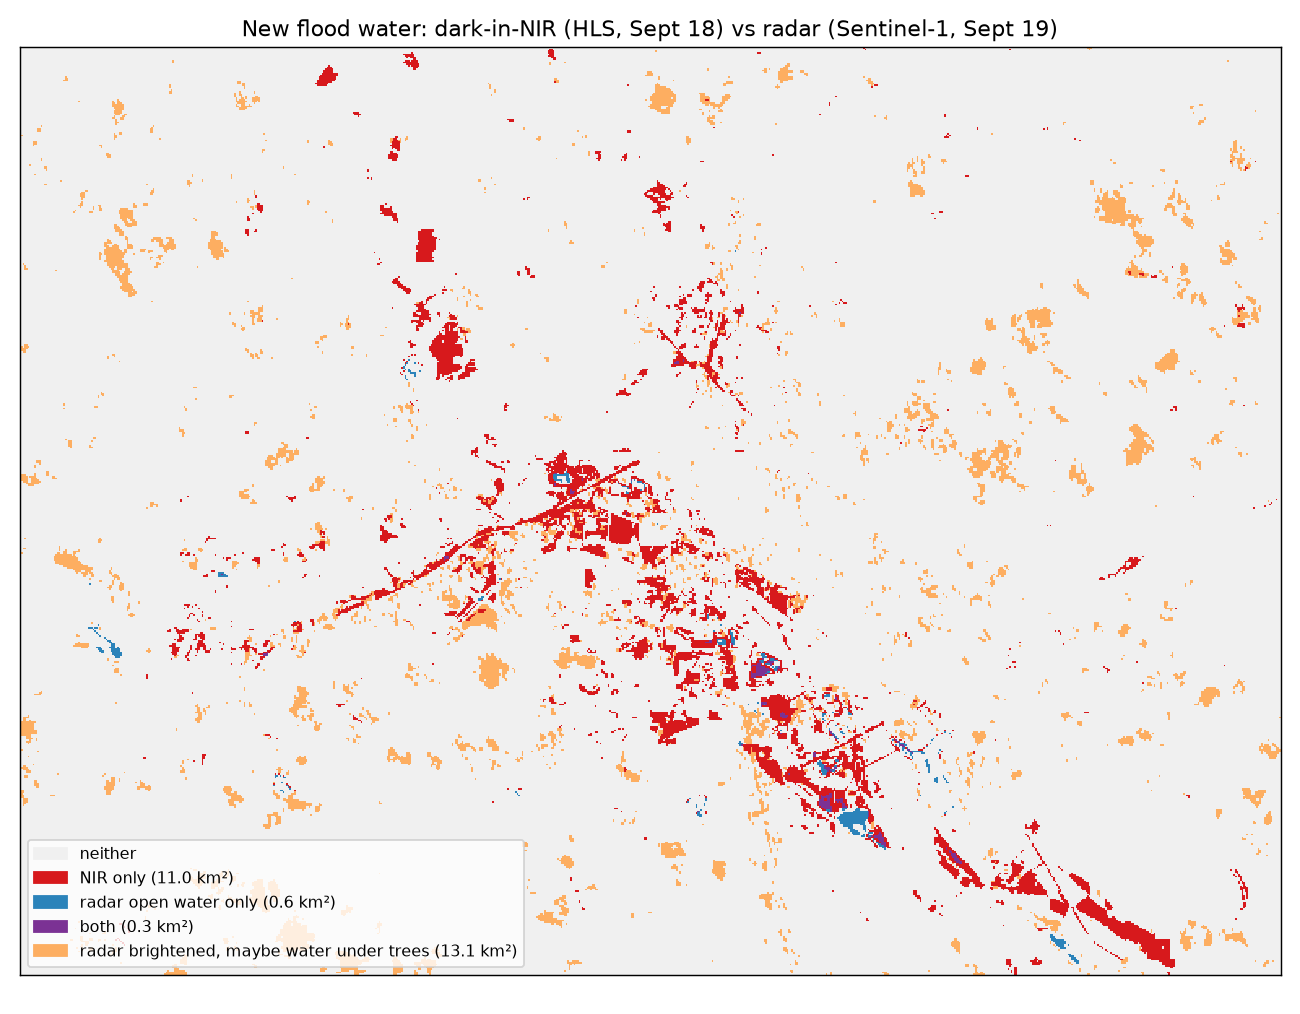

In [4]:
display(Image(filename='../figures/03_radar_vs_nir_map.png'))

## Referee: NOAA airplane photos (Sept 19-20) at random spots
A quick look at 4 random spots of each kind. This is **not** the full accuracy grade; that needs many more spots (next step).

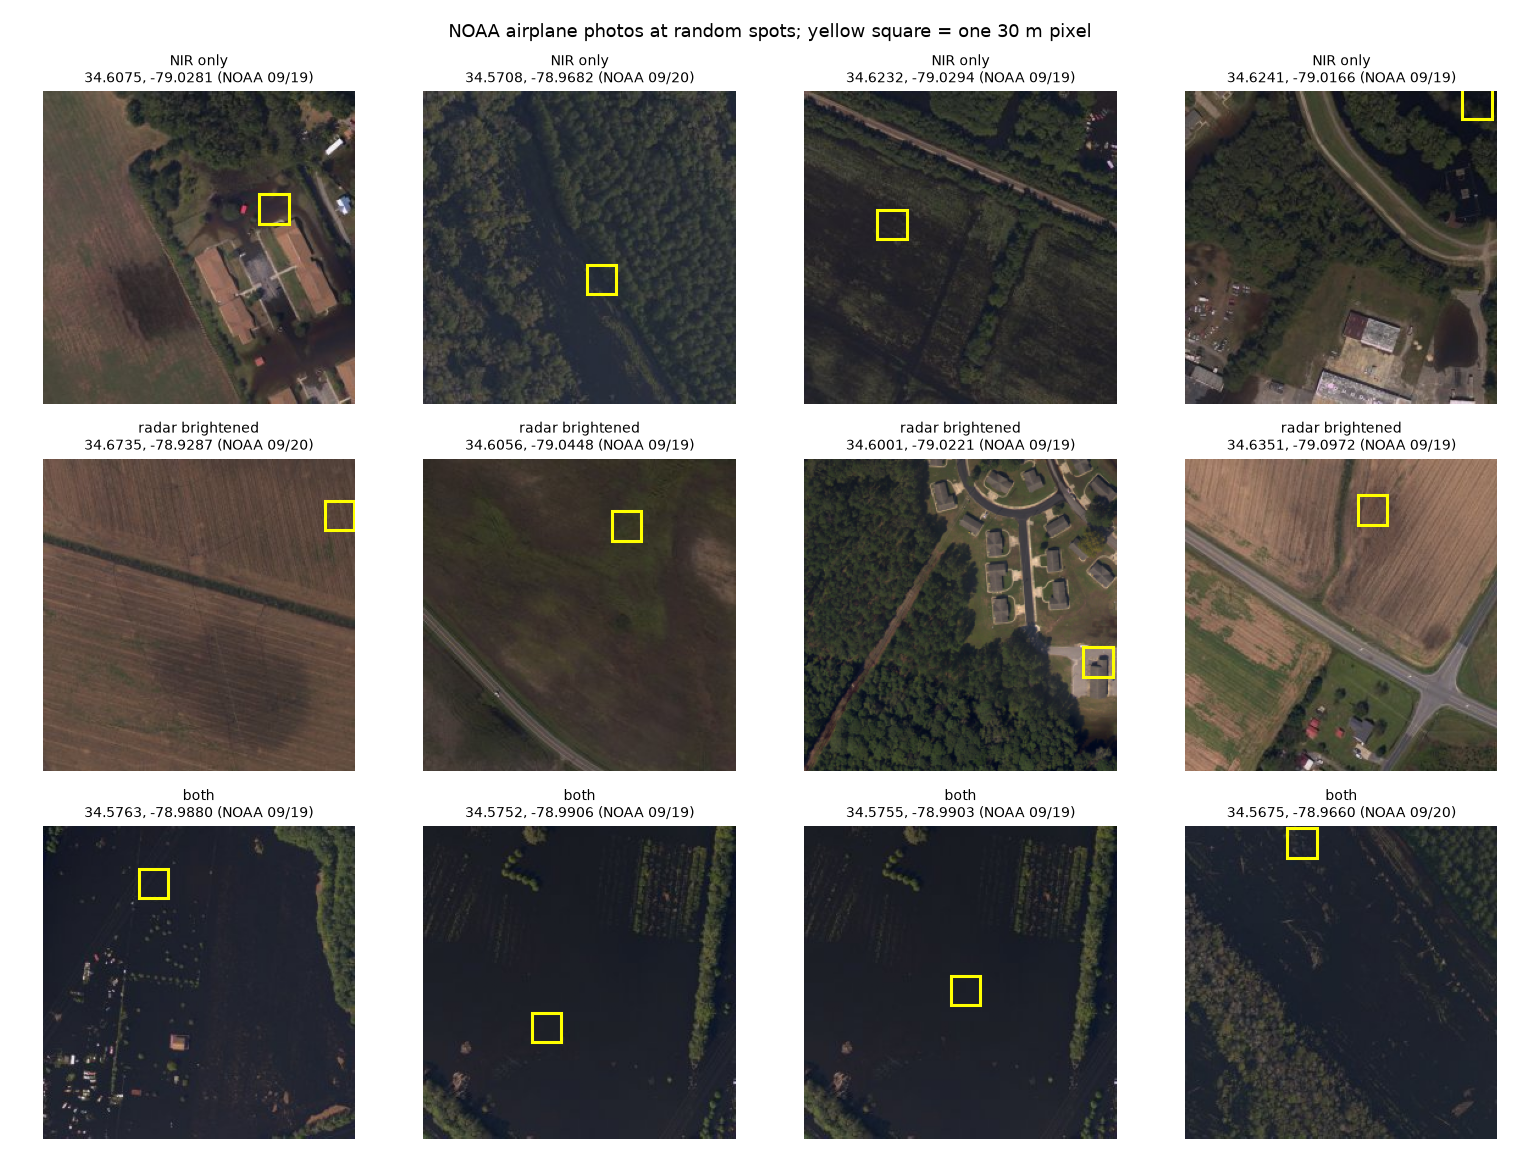

In [5]:
display(Image(filename='../figures/03_noaa_spot_check.png'))

## What we learned
- **Radar and near-infrared barely agree** (overlap about 2-3%). Radar finds only 0.9 km² of new open water; dark-in-NIR finds 11.3 km².
- In NIR-flood pixels, radar brightness barely changed (median -9.7 → -9.5 dB): radar sees them as land.
- **NOAA photos (12 spots):** "both" spots are deep open flood water. "NIR only" spots are mostly real flood too: shallow water with plants or trees sticking out, which makes the water surface rough for radar. "Radar brightened" spots are dry-looking plowed fields and houses, not water under trees.
- So far, near-infrared looks closer to the truth than this simple radar rule. **Caveats:** only 12 spots; radar is 1.5 days later than the HLS photo; we used only one radar band (VV) and one cutoff.